**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_036_초급_분류_공공자전거수요예측

### **웰니스스마트의 <span style="color:darkgreen">자전거 부족 여부</span> 예측 프로젝트**
---

- 도메인 : 공공자전거 수요 예측
- 목  표 : 대여소의 자전거 부족 여부를 예측하는 인공지능모델 개발
- 운영팀은 기상·시간 정보로 수요를 예측해 자전거 재배치를 효율화하려 한다.
- 시간대별 자전거 쏠림으로 웰니스스마트의 재배치 비용이 커지고 있다.
- 분석에는 약 760건 규모의 대여소 데이터가 제공된다.
- 모델이 자전거 부족 여부를 신뢰할 만한 수준으로 예측하면 현업의 대응 비용을 줄일 수 있을 것으로 기대한다.

---

#### **[유의사항]**
- 각 문항의 답은 `# (번호) 정답을 입력하세요` 셀의 `정답01` ~ `정답14` 변수에 **값만** 입력합니다. 채점은 이 값으로만 합니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 웰니스스마트의 데이터로 대여소의 자전거 부족 여부를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, corr, quantile, reset_index, drop, dropna, sum, isnull, loc, value_counts, isin, get_dummies, info, Series, idxmax, columns, shape) · seaborn(heatmap, jointplot) · matplotlib(show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, StandardScaler, fit_transform, transform, LogisticRegression, fit, DecisionTreeClassifier, feature_importances_, predict, accuracy_score) · TensorFlow(Keras)(Sequential, EarlyStopping, ModelCheckpoint, compile, fit, Dense, BatchNormalization, history)
- 난이도 : 초급 (설계 난이도 점수 2.54 / 5)
- 예상 소요 시간 : 약 114분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 공공자전거 수요 예측 (교통·물류)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- shortage              : 자전거 부족 여부 (0: Enough, 1: Shortage)
- sampleId              : 표본 식별번호
- tempC                 : 기온(℃)
- windMs                : 풍속(m/s)
- rainfallMm            : 강수량(mm)
- dustPm10              : 미세먼지(㎍/㎥)
- dockCnt               : 거치대 수
- stationPop            : 반경 500m 거주 인구(천명)
- prevHourRent          : 직전 시간 대여 수
- season                : 계절 (복수 값은 | 로 결합되어 있음)
- holiday               : 휴일 여부
- district              : 구역

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 데이터 분석에 널리 사용되는 파이썬 라이브러리 pandas 를 사용하려고 합니다. 별칭(alias)을 pd 로 해서 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd) | 난이도: 기초 | 예상 시간: 3분</sub>

- 불러올 라이브러리 : `pandas`
- 별칭(alias) : `pd`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 답안 셀에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [2]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import pandas as pd

In [3]:
# (1) 정답을 입력하세요 — `정답01` 에 값만 넣고 실행하세요

정답01 = 'pandas'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 6글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pan___ as pd

정답01 = 'pan___'   # 빈칸에 넣은 단어
```

</details>

### **2. 모델을 만들 데이터를 파일에서 읽어 들이려 합니다. pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 data 에 할당하고 첫 5개 행을 출력하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 아래 안내대로 코드를 작성하고 실행하세요
    - 읽은 결과를 담을 변수 : data / 파일은 본 문제/답안지와 동일한 경로에 있습니다
    - 읽어 올 파일 : data.csv
- **[정답02]** 읽어 온 데이터의 **열(column)의 개수** 를 작성하세요
- 답안 : **[정답02]** 의 값만 답안 셀에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [8]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
import pandas as pd

data = pd.read_csv('./data.csv')
data.head(5)
data.shape[1]


12

In [9]:
# (2) 정답을 입력하세요 — `정답02` 에 값만 넣고 실행하세요

정답02 = 12

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요. 읽어 온 data 로 열(column)의 개수를 직접 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`, `shape`, `select_dtypes`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

data = pd.read_csv('./data.csv')
data.head(5)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(data.shape[__])
```

</details>

### **3. 수치형 변수들 사이의 상관관계를 파악하고자 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(corr) · seaborn(heatmap) · matplotlib(show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- 아래 변수들의 상관계수 행렬을 구해 변수 `corr_df` 에 저장하고, seaborn heatmap(수치 표시 annot=True)으로 시각화하세요
    - 대상 데이터프레임 : data
    - 대상 변수 : 직전 시간 대여 수(prevHourRent), 기온(℃)(tempC), 강수량(mm)(rainfallMm), 풍속(m/s)(windMs), 미세먼지(㎍/㎥)(dustPm10)
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 답안 셀에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

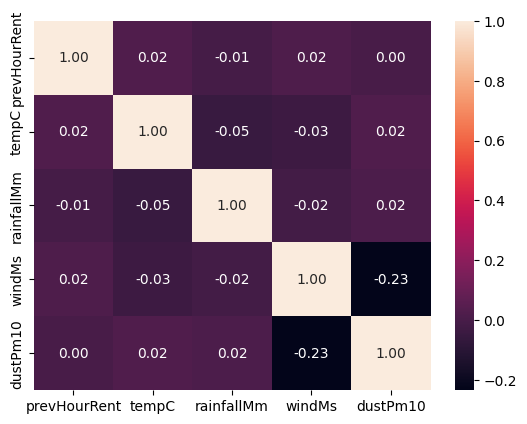

In [10]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

corr_df = data[['prevHourRent', 'tempC', 'rainfallMm', 'windMs', 'dustPm10']].corr()
sns.heatmap(corr_df, annot=True, fmt='.2f')
plt.show()

In [11]:
# (3) 정답을 입력하세요 — `정답03` 에 값만 넣고 실행하세요

정답03 = 'annot'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

선택한 컬럼들만 골라 상관계수 행렬을 만든 뒤 히트맵으로 그립니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `.corr()`, `sns.heatmap`. 정답은 5글자이고 첫 글자는 `a` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

corr_df = data[['prevHourRent', 'tempC', 'rainfallMm', 'windMs', 'dustPm10']].corr()
sns.heatmap(corr_df, ann__=True, fmt='.2f')
plt.show()

정답03 = 'ann__'   # 빈칸에 넣은 단어
```

</details>

### **4. 그래프를 통해 미세먼지(㎍/㎥)(dustPm10)와(과) 강수량(mm)(rainfallMm)의 분포와 관계를 함께 확인하고자 합니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(jointplot) · matplotlib(show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- 대상 데이터프레임 : data
- seaborn 의 jointplot 으로 시각화하세요
- X축: dustPm10, Y축: rainfallMm
- 그래프 종류(kind)는 'scatter' 로 설정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 답안 셀에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

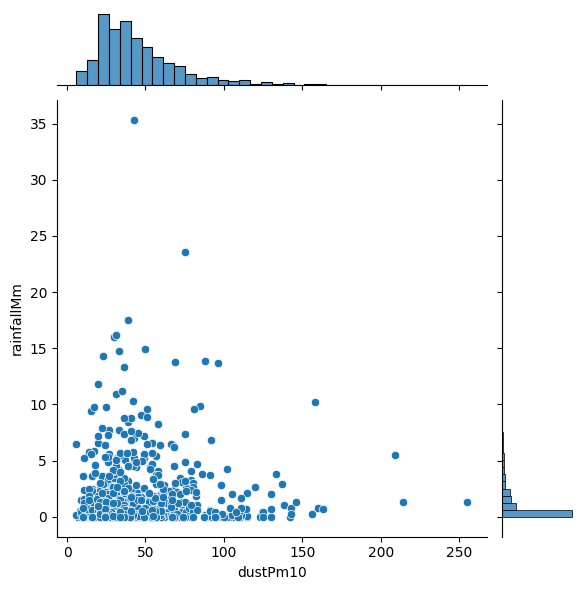

In [12]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.jointplot(data=data, x='dustPm10', y='rainfallMm', kind='scatter')
plt.show()

In [13]:
# (4) 정답을 입력하세요 — `정답04` 에 값만 넣고 실행하세요

정답04 = 'jointplot'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

두 변수의 관계와 각각의 분포를 한 그림에 그리는 그래프입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.jointplot`. 정답은 9글자이고 첫 글자는 `j` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.joint____(data=data, x='dustPm10', y='rainfallMm', kind='scatter')
plt.show()

정답04 = 'joint____'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 기온(℃)(tempC) 컬럼의 이상치를 IQR 기준으로 제거할 계획입니다. 제시된 가이드에 맞춰 처리하세요.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, reset_index, drop) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- 대상 데이터프레임 : data
- 사분위수(Q1, Q3)와 IQR 을 계산하세요
- lower_fence = Q1 - 2.0 x IQR, upper_fence = Q3 + 2.0 x IQR 로 정의하세요
- tempC 이(가) 두 fence 밖에 있는 행을 삭제하세요
- 식별자 컬럼 sampleId 도 삭제하고 인덱스를 0부터 다시 매겨 data_temp 에 담으세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답05]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답05]** 의 값만 답안 셀에 `정답05 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [14]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

q1 = data['tempC'].quantile(0.25)
q3 = data['tempC'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 2.0 * iqr
upper_fence = q3 + 2.0 * iqr

is_out = (data['tempC'] > upper_fence) | (data['tempC'] < lower_fence)
data_temp = data[~is_out].drop(columns=['sampleId']).reset_index(drop=True)

In [15]:
# (5) 정답을 입력하세요 — `정답05` 에 값만 넣고 실행하세요

정답05 = 'quantile'

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

분위수로 fence 를 계산하고, 범위 밖 여부를 불리언으로 만든 뒤 반대로 선택합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `drop`, `reset_index`. 정답은 8글자이고 첫 글자는 `q` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
q1 = data['tempC'].quan____(0.25)
q3 = data['tempC'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 2.0 * iqr
upper_fence = q3 + 2.0 * iqr

is_out = (data['tempC'] > upper_fence) | (data['tempC'] < lower_fence)
data_temp = data[~is_out].drop(columns=['sampleId']).reset_index(drop=True)

정답05 = 'quan____'   # 빈칸에 넣은 단어
```

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. AI모델링할 때 부정적 영향이 없도록 아래 안내대로 결측치를 처리하세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 5번 `data_temp`
- 대상 데이터프레임 : data_temp
- 결측치 개수를 확인한 후에 결측치가 있는 행을 모두 삭제하세요
- 전처리가 반영된 데이터프레임은 변수명 data_na 에 보관하세요
- 결측치가 사라졌는지 확인하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답06]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답06]** 의 값만 답안 셀에 `정답06 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [16]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

print( '결측치 처리 전\n', data_temp.isnull().sum() )
data_na = data_temp.dropna()
print( '결측치 처리 후\n', data_na.isnull().sum() )

결측치 처리 전
 shortage         0
tempC            0
windMs           8
rainfallMm       0
dustPm10         0
dockCnt          0
stationPop      42
prevHourRent     0
season           0
holiday          0
district        29
dtype: int64
결측치 처리 후
 shortage        0
tempC           0
windMs          0
rainfallMm      0
dustPm10        0
dockCnt         0
stationPop      0
prevHourRent    0
season          0
holiday         0
district        0
dtype: int64


In [ ]:
# (6) 정답을 입력하세요 — `정답06` 에 값만 넣고 실행하세요

정답06 = 'dropna'

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 결측치가 있는 행을 삭제하는 메서드입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`, `dropna`. 정답은 6글자이고 첫 글자는 `d` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
print( '결측치 처리 전\n', data_temp.isnull().sum() )
data_na = data_temp.dro___()
print( '결측치 처리 후\n', data_na.isnull().sum() )

정답06 = 'dro___'   # 빈칸에 넣은 단어
```

</details>

### **7. 원-핫 인코딩(One-Hot Encoding)은 범주형 데이터를 1과 0의 이진형 벡터로 변환하는 방법입니다. 제시된 가이드에 맞춰 범주형 데이터를 처리하고 인코딩하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(loc, value_counts, isin, get_dummies) | 난이도: 어려움 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `data_na`
- 다음 지침에 따라 데이터를 처리하는 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : data_na
    - 계절(season) 의 값 '가을|겨울', '가을|봄', '가을|여름' 을(를) '가을' 으로 치환하세요
    - 계절(season) 의 값 '겨울|가을', '겨울|봄', '겨울|여름' 을(를) '겨울' 으로 치환하세요
    - 계절(season) 의 값 '봄|가을', '봄|겨울', '봄|여름' 을(를) '봄' 으로 치환하세요
    - 계절(season) 의 값 '여름|가을', '여름|겨울', '여름|봄' 을(를) '여름' 으로 치환하세요
    - 치환 후 범주별 개수를 출력하세요
- 남은 문자열 컬럼을 모두 원-핫 인코딩(get_dummies, drop_first=True)하는데 오류가 발생하고 있습니다. 코드의 오류를 정정하고 결과를 data_preset 에 보관하세요
- **[정답07]** 인코딩 후 data_preset 의 **전체 컬럼 개수**는 몇 개인가요?
- 답안 : **[정답07]** 의 값만 답안 셀에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [22]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요 (채점하지 않음)

data_na.loc[data_na['season'].isin(['가을|겨울', '가을|봄', '가을|여름']), 'season'] = '가을'
data_na.loc[data_na['season'].isin(['겨울|가을', '겨울|봄', '겨울|여름']), 'season'] = '겨울'
data_na.loc[data_na['season'].isin(['봄|가을', '봄|겨울', '봄|여름']), 'season'] = '봄'
data_na.loc[data_na['season'].isin(['여름|가을', '여름|겨울', '여름|봄']), 'season'] = '여름'

print(data_na['season'].loc())

In [23]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

data_preset = pd.get_dummies(data=data_na, columns=['season', 'holiday', 'district'], drop_first=True)
data_preset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 668 entries, 0 to 744
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   shortage      668 non-null    int64  
 1   tempC         668 non-null    float64
 2   windMs        668 non-null    float64
 3   rainfallMm    668 non-null    float64
 4   dustPm10      668 non-null    float64
 5   dockCnt       668 non-null    float64
 6   stationPop    668 non-null    float64
 7   prevHourRent  668 non-null    float64
 8   season_겨울     668 non-null    bool   
 9   season_봄      668 non-null    bool   
 10  season_여름     668 non-null    bool   
 11  holiday_휴일    668 non-null    bool   
 12  district_대학   668 non-null    bool   
 13  district_도심   668 non-null    bool   
 14  district_주거   668 non-null    bool   
dtypes: bool(7), float64(7), int64(1)
memory usage: 51.5 KB


In [24]:
# (7) 정답을 입력하세요 — `정답07` 에 값만 넣고 실행하세요

정답07 = 15


<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

빈칸을 채워 치환 코드를 완성해 실행하세요. 해당 위치에 들어갈 함수/옵션 이름을 떠올려 보세요. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `isin`, `loc`, `value_counts`, `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

data_na.loc[data_na['season'].isin(['가을|겨울', '가을|봄', '가을|여름']), 'season'] = '가을'
data_na.loc[data_na['season'].isin(['겨울|가을', '겨울|봄', '겨울|여름']), 'season'] = '겨울'
data_na.loc[data_na['season'].isin(['봄|가을', '봄|겨울', '봄|여름']), 'season'] = '봄'
data_na.loc[data_na['season'].isin(['여름|가을', '여름|겨울', '여름|봄']), 'season'] = '여름'

print(data_na['season'].value_counts())

data_preset = pd.get_dummies(data=data_na, columns=['season', 'holiday', 'district'], drop_first=True)
data_preset.info()

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
data_preset.shape[__]
```

</details>

### **8. 학습한 모델을 공정하게 평가하려면 학습에 쓰지 않은 검증 데이터가 필요합니다. 데이터를 훈련용과 검증용으로 나누려 합니다. 아래 가이드에 따라 분리하세요.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 7번 `data_preset`
- 대상 데이터프레임 : data_preset
- 자전거 부족 여부(shortage) 을(를) 목표 변수 y 로 두고, 이를 뺀 나머지 컬럼으로 X 를 만드세요
- 변수명 : X_train, X_valid, y_train, y_valid (훈련 피처/검증 피처/훈련 레이블/검증 레이블)
- 난수 시드(random_state)는 7 로 설정하세요
- scikit-learn 의 train_test_split 함수를 활용하세요
- 훈련 65%, 검증 35% 비율로 나누세요 (train_size=0.65)
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답08]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답08]** 의 값만 답안 셀에 `정답08 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [25]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

from sklearn.model_selection import train_test_split

X = data_preset.drop('shortage', axis=1)
y = data_preset['shortage']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.65, random_state=7)

In [26]:
# (8) 정답을 입력하세요 — `정답08` 에 값만 넣고 실행하세요

정답08 = 'random_state'

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`. 정답은 12글자이고 첫 글자는 `r` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.model_selection import train_test_split

X = data_preset.drop('shortage', axis=1)
y = data_preset['shortage']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.65, random______=7)

정답08 = 'random______'   # 빈칸에 넣은 단어
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (표준화(평균 0, 표준편차 1))**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(StandardScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 제시된 가이드에 맞춰 스케일링 처리하는데 에러가 나고 있습니다. 코드의 오류를 정정하세요
    - sklearn.preprocessing 에서 StandardScaler 를 import 하세요
    - StandardScaler 를 sc 변수에 지정하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 담으세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 보관하세요
- **[정답09]** StandardScaler 적용 후 검증 데이터(X_valid)의 **최댓값**을 소수 둘째 자리까지 기입하세요
- 답안 : **[정답09]** 의 값만 답안 셀에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [28]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)
print(X_valid.max())

13.245989183052114


In [30]:
# (9) 정답을 입력하세요 — `정답09` 에 값만 넣고 실행하세요

정답09 = 13.25

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최댓값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.max`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.max(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 자전거 부족 여부(shortage)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. LogisticRegression와(과) DecisionTree는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(LogisticRegression, fit, DecisionTreeClassifier) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- LogisticRegression 모델을 아래와 같이 만들어 `lr` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : C=0.1
    - 최대 반복 횟수(max_iter) : 1000
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=8, min_samples_leaf=5
    - 난수 시드(random_state) : 1
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `dt`(DecisionTree) 의 **훈련 데이터** 점수 `dt.score(X_train, y_train)` (정확도(accuracy))를 소수점 셋째 자리까지 작성하세요
- 답안 : **[정답10]** 의 값만 답안 셀에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [33]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

lr = LogisticRegression(C=0.1,max_iter=1000)
lr.fit(X_train, y_train)

dt = DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=1)
dt.fit(X_train, y_train)

dt.score(X_train, y_train)

0.8317972350230415

In [ ]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)



In [ ]:
# (10) 정답을 입력하세요 — `정답10` 에 값만 넣고 실행하세요

정답10 = 0.832

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 학습된 모델의 score 메서드에 훈련 데이터를 넣고 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `LogisticRegression`, `fit`, `DecisionTreeClassifier`, `score`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(C=0.1, max_iter=1000)
lr.fit(X_train, y_train)

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=1)
dt.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(dt.score(X_train, y_train), __)
```

</details>

### **11. DecisionTree 모델이 예측에 가장 크게 쓴 변수가 무엇인지 확인하려 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(Series, idxmax, columns) · scikit-learn(feature_importances_) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `dt`
- 학습된 DecisionTree 모델 `dt` 의 변수중요도를 변수명(X.columns)을 인덱스로 하는 Series `fi` 로 만들고, 가장 큰 값의 변수명을 `idxmax()` 로 구해 `top_feature` 에 담으세요
- **[정답11]** `top_feature` 의 값(변수명)을 기입하세요
- 답안 : **[정답11]** 의 값만 답안 셀에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [35]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
top_feature = X.columns[dt.feature_importances_.argmax()]
print(top_feature)


prevHourRent


In [36]:
# (11) 정답을 입력하세요 — `정답11` 에 값만 넣고 실행하세요

정답11 = 'prevHourRent'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

중요도 배열에 변수 이름 인덱스를 붙여 Series 로 만든 뒤 최댓값의 이름을 구합니다. top_feature 를 출력하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `pd.Series`, `feature_importances_`, `idxmax`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

fi = pd.Series(dt.feature_importances_, index=X.columns)
top_feature = fi.idxmax()

# [정답11] 실행한 결과를 입력하세요
print(top_feature)
```

</details>

### **12. 앞서 학습시킨 LogisticRegression와(과) DecisionTree 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, accuracy_score) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`, `lr`
- 아래 가이드에 따라 각 모델의 Accuracy(정확도) 를 산출하려는데 에러가 나고 있습니다. 코드의 오류를 수정하세요
    - 앞서 학습시킨 lr 와 dt 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 Accuracy(정확도) 값을 각각 lr_score, dt_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 Accuracy(정확도) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (LogisticRegression / DecisionTree 중 하나)
- 답안 : **[정답12]** 의 값만 답안 셀에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [37]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import accuracy_score

y_pred_lr = lr.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

lr_score = accuracy_score(y_valid, y_pred_lr)
dt_score = accuracy_score(y_valid, y_pred_dt)
print(lr_score, dt_score)

0.717948717948718 0.6666666666666666


In [38]:
# (12) 정답을 입력하세요 — `정답12` 에 값만 넣고 실행하세요

정답12 = 'LogisticRegression'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

Accuracy(정확도) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 클수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import accuracy_score

y_pred_lr = lr.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

lr_score = accuracy_score(y_valid, y_pred_lr)
dt_score = accuracy_score(y_valid, y_pred_dt)
print(lr_score, dt_score)

# [정답12] 실행한 결과를 입력하세요
print(lr_score, dt_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [39]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

### **13. 자전거 부족 여부(shortage)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 가이드를 참고해서 모델링하고 학습을 수행하십시오.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, ModelCheckpoint, compile) | 난이도: 보통 | 예상 시간: 13분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- tensorflow framework 를 사용하세요
- 은닉층은 Dense 레이어 2개(노드 수 [32, 16]), 활성화 함수는 'elu' 로 하세요
- EarlyStopping 으로 14번의 epoch 동안 val_loss 가 향상되지 않으면 훈련을 중지(restore_best_weights=True)하도록 설정하고 estop 변수에 저장하세요
- ModelCheckpoint('best_model.keras', save_best_only=True)를 callbacks 에 함께 넣으세요
- Dropout 층은 사용하지 않습니다
- 각 Dense 층 뒤에 BatchNormalization 층을 추가하세요
- 출력층은 노드 1개, activation='sigmoid' 로 하세요
- optimizer 는 nadam, loss 는 binary_crossentropy, metrics 는 [accuracy] 로 지정해서 모델을 컴파일하세요
- batch_size 는 16, epochs 는 20 로 학습하고 학습정보는 history 변수에 보관하세요 (검증 데이터: X_valid, 검증 레이블)
- 안내하지 않은 파라미터는 지정하지 마세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답13]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답13]** 의 값만 답안 셀에 `정답13 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [43]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요
ㅌ

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


TypeError: TensorFlowTrainer.fit() got an unexpected keyword argument 'validation_size'. Did you mean 'validation_split'?

In [ ]:
# (13) 정답을 입력하세요 — `정답13` 에 값만 넣고 실행하세요

정답13 = None

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드의 모델 구조·학습 조건을 코드의 각 줄과 대응시켜 보세요. fit 에서 검증용 데이터를 지정하는 인자입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`. 정답은 15글자이고 첫 글자는 `v` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
model = Sequential([
    Dense(32, activation='elu', input_dim=X_train.shape[1]),
    BatchNormalization(),
    Dense(16, activation='elu'),
    BatchNormalization(),
    Dense(1, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=14, restore_best_weights=True)
cb_list = [estop]
ckpt = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
cb_list.append(ckpt)

model.compile(optimizer='nadam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=16,
                    validati_______=(X_valid, y_valid),
                    callbacks=cb_list)

정답13 = 'validati_______'   # 빈칸에 넣은 단어
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Loss와(과) 검증 Loss의 변화를 그래프로 시각화하십시오.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 13번 `history`
- 1개의 그래프에 학습 Loss 과 검증 Loss 2가지를 모두 표시하세요
- 두 선의 범례 : 'train', 'val'
- 그래프의 타이틀은 'Model Loss' 로, X축 이름은 'Epochs', Y축 이름은 'Loss' 로 표시하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답14]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답14]** 의 값만 답안 셀에 `정답14 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [ ]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

plt.plot(____.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()

In [ ]:
# (14) 정답을 입력하세요 — `정답14` 에 값만 넣고 실행하세요

정답14 = None

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. fit 이 돌려준 학습 기록 객체의 변수명입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 7글자이고 첫 글자는 `h` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.plot(hist___.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()

정답14 = 'hist___'   # 빈칸에 넣은 단어
```

</details>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.